In [2]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_wine, load_breast_cancer
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.decomposition import PCA
from sklearn.metrics import (
    silhouette_score,
    adjusted_rand_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report
)
from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    cross_validate,
    GridSearchCV
)
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

RANDOM_STATE = 42

print("All libraries imported successfully!")


All libraries imported successfully!


In [3]:

wine = load_wine(as_frame=True)

X = wine.data.copy()
reference_labels = wine.target.copy()

print("Dataset shape:", X.shape)
print("Number of records:", X.shape[0])
print("Number of features:", X.shape[1])

display(X.head())

print("\nMissing values per column:")
print(X.isnull().sum())


Dataset shape: (178, 13)
Number of records: 178
Number of features: 13


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0



Missing values per column:
alcohol                         0
malic_acid                      0
ash                             0
alcalinity_of_ash               0
magnesium                       0
total_phenols                   0
flavanoids                      0
nonflavanoid_phenols            0
proanthocyanins                 0
color_intensity                 0
hue                             0
od280/od315_of_diluted_wines    0
proline                         0
dtype: int64


In [4]:

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("Original data shape:", X.shape)
print("Scaled data shape:", X_scaled.shape)
print("Data standardised successfully!")


Original data shape: (178, 13)
Scaled data shape: (178, 13)
Data standardised successfully!


Elbow method results:


,k,inertia
0,2,1658.758852
1,3,1277.928489
2,4,1175.428333
3,5,1109.512739
4,6,1046.002333
5,7,981.595233
6,8,935.201211


Silhouette scores:


,k,silhouette_score
0,2,0.259317
1,3,0.284859
2,4,0.260170
3,5,0.201619
4,6,0.237167
5,7,0.203628
6,8,0.157014


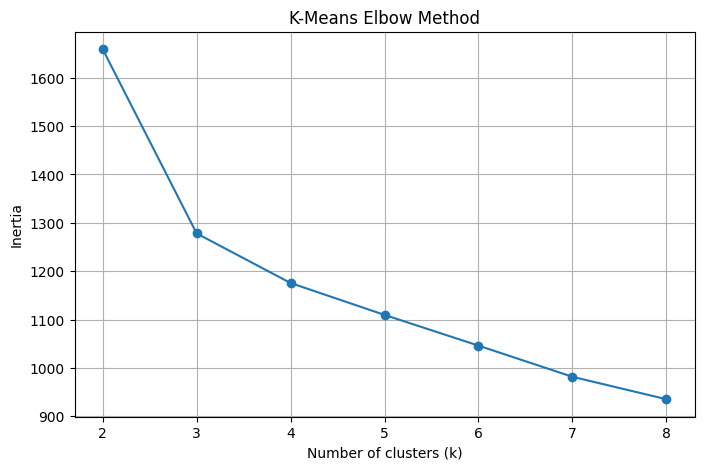

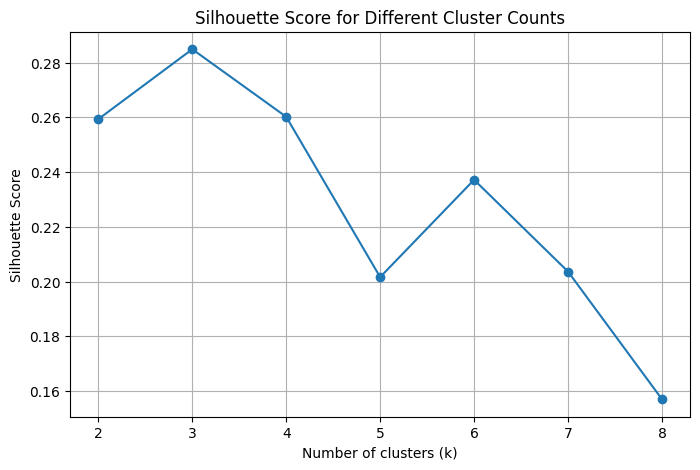

Best k among tested values: 3


In [5]:

inertia_rows = []
silhouette_rows = []

for k in range(2, 9):
    model = KMeans(
        n_clusters=k,
        random_state=RANDOM_STATE,
        n_init=10
    )

    labels = model.fit_predict(X_scaled)

    inertia_rows.append({
        "k": k,
        "inertia": model.inertia_
    })

    silhouette_rows.append({
        "k": k,
        "silhouette_score": silhouette_score(X_scaled, labels)
    })

inertia_df = pd.DataFrame(inertia_rows)
silhouette_df = pd.DataFrame(silhouette_rows)

print("Elbow method results:")
display(inertia_df)

print("Silhouette scores:")
display(silhouette_df)

plt.figure(figsize=(8, 5))
plt.plot(inertia_df["k"], inertia_df["inertia"], marker="o")
plt.xlabel("Number of clusters (k)")
plt.ylabel("Inertia")
plt.title("K-Means Elbow Method")
plt.xticks(range(2, 9))
plt.grid(True)
plt.show()

plt.figure(figsize=(8, 5))
plt.plot(
    silhouette_df["k"],
    silhouette_df["silhouette_score"],
    marker="o"
)
plt.xlabel("Number of clusters (k)")
plt.ylabel("Silhouette Score")
plt.title("Silhouette Score for Different Cluster Counts")
plt.xticks(range(2, 9))
plt.grid(True)
plt.show()

best_k = int(
    silhouette_df.loc[
        silhouette_df["silhouette_score"].idxmax(), "k"
    ]
)

print("Best k among tested values:", best_k)



In [6]:

kmeans = KMeans(
    n_clusters=best_k,
    random_state=RANDOM_STATE,
    n_init=10
)

kmeans_labels = kmeans.fit_predict(X_scaled)

hierarchical = AgglomerativeClustering(
    n_clusters=best_k,
    linkage="ward"
)

hierarchical_labels = hierarchical.fit_predict(X_scaled)

comparison = pd.DataFrame([
    {
        "Algorithm": "K-Means",
        "Clusters": best_k,
        "Silhouette Score": silhouette_score(
            X_scaled, kmeans_labels
        )
    },
    {
        "Algorithm": "Hierarchical Clustering (Ward)",
        "Clusters": best_k,
        "Silhouette Score": silhouette_score(
            X_scaled, hierarchical_labels
        )
    }
])

display(comparison)

print("\nK-Means cluster sizes:")
print(pd.Series(kmeans_labels).value_counts().sort_index())

print("\nHierarchical cluster sizes:")
print(pd.Series(hierarchical_labels).value_counts().sort_index())


,Algorithm,Clusters,Silhouette Score
0,K-Means,3,0.284859
1,Hierarchical Clustering (Ward),3,0.277444



K-Means cluster sizes:
0    65
1    51
2    62
Name: count, dtype: int64

Hierarchical cluster sizes:
0    58
1    56
2    64
Name: count, dtype: int64


Variance explained by first two principal components: 0.5541


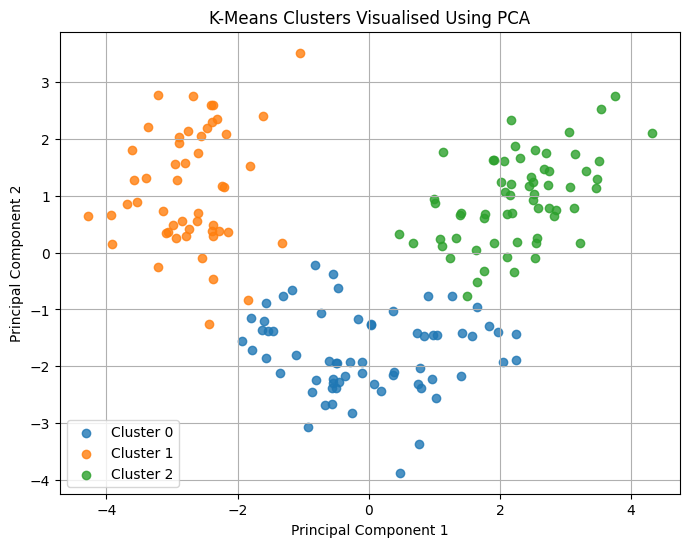

In [7]:

pca = PCA(n_components=2, random_state=RANDOM_STATE)
X_pca = pca.fit_transform(X_scaled)

explained_variance = pca.explained_variance_ratio_.sum()

print(
    "Variance explained by first two principal components:",
    round(explained_variance, 4)
)

plt.figure(figsize=(8, 6))

for cluster_id in sorted(np.unique(kmeans_labels)):
    mask = kmeans_labels == cluster_id

    plt.scatter(
        X_pca[mask, 0],
        X_pca[mask, 1],
        label=f"Cluster {cluster_id}",
        alpha=0.8
    )

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("K-Means Clusters Visualised Using PCA")
plt.legend()
plt.grid(True)
plt.show()


In [8]:

# Reference labels are used only for external evaluation.
# They were not used to train the clustering algorithms.

kmeans_ari = adjusted_rand_score(
    reference_labels, kmeans_labels
)

hierarchical_ari = adjusted_rand_score(
    reference_labels, hierarchical_labels
)

print("K-Means Adjusted Rand Index:", round(kmeans_ari, 4))
print("Hierarchical Adjusted Rand Index:", round(hierarchical_ari, 4))


K-Means Adjusted Rand Index: 0.8975
Hierarchical Adjusted Rand Index: 0.7899


In [9]:

cancer = load_breast_cancer(as_frame=True)

X_class = cancer.data
y_class = cancer.target

X_train, X_test, y_train, y_test = train_test_split(
    X_class,
    y_class,
    test_size=0.2,
    random_state=RANDOM_STATE,
    stratify=y_class
)

classifier = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(max_iter=5000))
])

classifier.fit(X_train, y_train)

y_pred = classifier.predict(X_test)
y_prob = classifier.predict_proba(X_test)[:, 1]

metrics = pd.DataFrame([{
    "Accuracy": accuracy_score(y_test, y_pred),
    "Precision": precision_score(y_test, y_pred),
    "Recall": recall_score(y_test, y_pred),
    "F1-score": f1_score(y_test, y_pred),
    "ROC-AUC": roc_auc_score(y_test, y_prob)
}])

display(metrics)

print(classification_report(
    y_test,
    y_pred,
    target_names=cancer.target_names
))


,Accuracy,Precision,Recall,F1-score,ROC-AUC
0,0.982456,0.986111,0.986111,0.986111,0.99537


              precision    recall  f1-score   support

   malignant       0.98      0.98      0.98        42
      benign       0.99      0.99      0.99        72

    accuracy                           0.98       114
   macro avg       0.98      0.98      0.98       114
weighted avg       0.98      0.98      0.98       114



Confusion Matrix:
[[41  1]
 [ 1 71]]


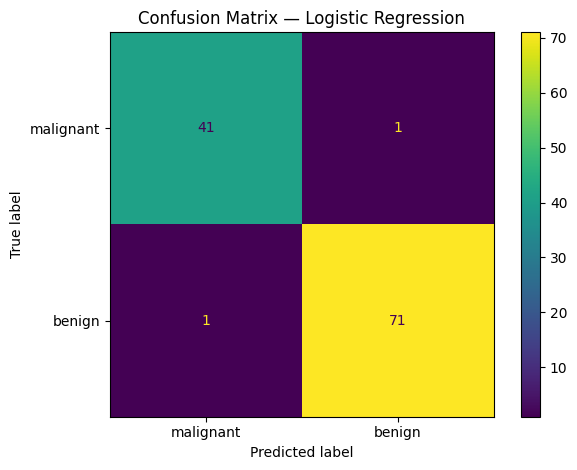

In [10]:

cm = confusion_matrix(y_test, y_pred)

print("Confusion Matrix:")
print(cm)

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    display_labels=cancer.target_names
)

plt.title("Confusion Matrix — Logistic Regression")
plt.tight_layout()
plt.show()


In [11]:

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE
)

cv_results = cross_validate(
    classifier,
    X_train,
    y_train,
    cv=cv,
    scoring=[
        "accuracy",
        "precision",
        "recall",
        "f1",
        "roc_auc"
    ],
    n_jobs=-1
)

cv_summary = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1-score",
        "ROC-AUC"
    ],
    "Mean 5-Fold CV": [
        cv_results["test_accuracy"].mean(),
        cv_results["test_precision"].mean(),
        cv_results["test_recall"].mean(),
        cv_results["test_f1"].mean(),
        cv_results["test_roc_auc"].mean()
    ],
    "Standard Deviation": [
        cv_results["test_accuracy"].std(),
        cv_results["test_precision"].std(),
        cv_results["test_recall"].std(),
        cv_results["test_f1"].std(),
        cv_results["test_roc_auc"].std()
    ]
})

display(cv_summary)


,Metric,Mean 5-Fold CV,Standard Deviation
0,Accuracy,0.978022,0.009829
1,Precision,0.979472,0.016229
2,Recall,0.985965,0.013129
3,F1-score,0.982544,0.007752
4,ROC-AUC,0.995872,0.004960


In [12]:

parameter_grid = {
    "model__C": [0.01, 0.1, 1, 10],
    "model__solver": ["liblinear"]
}

search = GridSearchCV(
    estimator=Pipeline([
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(max_iter=5000))
    ]),
    param_grid=parameter_grid,
    cv=cv,
    scoring="f1",
    n_jobs=-1
)

search.fit(X_train, y_train)

print("Best parameters:", search.best_params_)
print("Best mean cross-validation F1-score:", round(search.best_score_, 4))

tuned_predictions = search.best_estimator_.predict(X_test)

print(
    "Tuned model test F1-score:",
    round(f1_score(y_test, tuned_predictions), 4)
)


Best parameters: {'model__C': 0.1, 'model__solver': 'liblinear'}
Best mean cross-validation F1-score: 0.9861
Tuned model test F1-score: 0.9861


In [13]:

silhouette_df.to_csv(
    "YuvaIntern_Week3_Clustering_Silhouette_Results.csv",
    index=False
)

inertia_df.to_csv(
    "YuvaIntern_Week3_Elbow_Inertia_Results.csv",
    index=False
)

comparison.to_csv(
    "YuvaIntern_Week3_Clustering_Comparison.csv",
    index=False
)

metrics.to_csv(
    "YuvaIntern_Week3_Classification_Metrics.csv",
    index=False
)

cv_summary.to_csv(
    "YuvaIntern_Week3_CrossValidation_Results.csv",
    index=False
)

print("All five CSV result files exported successfully.")


All five CSV result files exported successfully.


## Conclusion

- K-Means clustering was evaluated across multiple cluster counts using inertia and silhouette score.
- Agglomerative clustering was compared with K-Means.
- PCA was used to visualize the clusters in two dimensions.
- Classification performance was evaluated using accuracy, precision, recall, F1-score, and ROC-AUC.
- Stratified cross-validation and hyperparameter tuning were used to assess and improve model performance.